# MRI Tumor detection

### Imports

In [1]:
import tensorflow as tf # Library for machine learning and deep learning
import numpy as np # Library for numerical computations
import matplotlib.pyplot as plt #Library for visualizations
from sklearn.model_selection import train_test_split # Library for splitting data into training and testing sets
import os # Library for interacting with the operating system
import pandas as pd # Library for data manipulation and analysis
from tensorflow.keras.preprocessing.image import ImageDataGenerator # Library for image data augmentation
from PIL import Image # Library for image processing

In [4]:
images = [] #eompty list to store images
labels = [] #empty list to store labels

for label in os.listdir("C:\\indianGuyPROJECT\\Brain Tumor MRI Dataset\\Dataset\\Dataset\\data"): #looping through the directories within the data folder
    folder = os.path.join("C:\\indianGuyPROJECT\\Brain Tumor MRI Dataset\\Dataset\\Dataset\\data", label) #joining the path of the data folder with the label
    print(folder) #printing the path of the folder

    for filename in os.listdir(folder): #Looping through the files within the folder, in this case, our images
        path = os.path.join(folder, filename) #joining the path of the folder with the filename

        image = Image.open(path).convert("RGB") #opening the image and converting it to RGB format using PIL (Python Imaging Library)
        image = image.resize((224, 224)) #resizing the image to 224x224 pixels
        images.append(np.array(image)) #converting the image to a numpy array and appending it to the images list
        labels.append(0 if label == "no tumor" else 1) #appending the label to the labels list, 0 for Banana_Rotten and 1 for Banana_Healthy

X = np.array(images) #converting the images list to a numpy array and assigning it to X
Y = np.array(labels) #converting the labels list to a numpy array and assigning it to Y


C:\indianGuyPROJECT\Brain Tumor MRI Dataset\Dataset\Dataset\data\no tumor
C:\indianGuyPROJECT\Brain Tumor MRI Dataset\Dataset\Dataset\data\tumor


In [5]:
print(X.shape) #printing the shape of the X array
print(Y.shape) #printing the shape of the Y array

(10093, 224, 224, 3)
(10093,)


### Exploratory Data Analysis

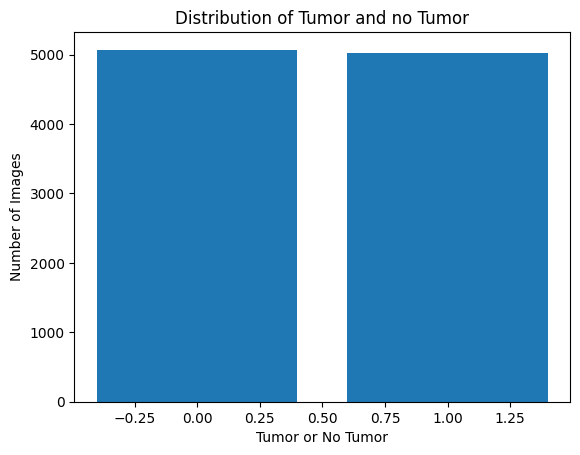

In [7]:
unique, counts = np.unique(Y, return_counts=True) #getting the unique values and their counts in the Y array

plt.bar(unique, counts) #creating a bar chart of the unique values and their counts
plt.xlabel("Tumor or No Tumor")
plt.ylabel("Number of Images")
plt.title("Distribution of Tumor and no Tumor")
plt.show() #displaying the bar chart

In [8]:
print(unique)

[0 1]


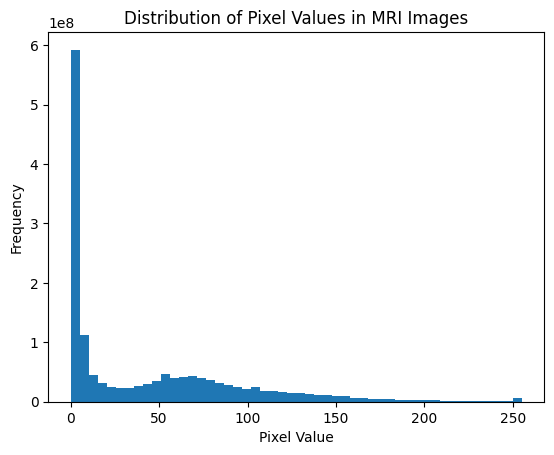

In [9]:
plt.hist(X.flatten(), bins = 50)
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values in MRI Images")
plt.show()

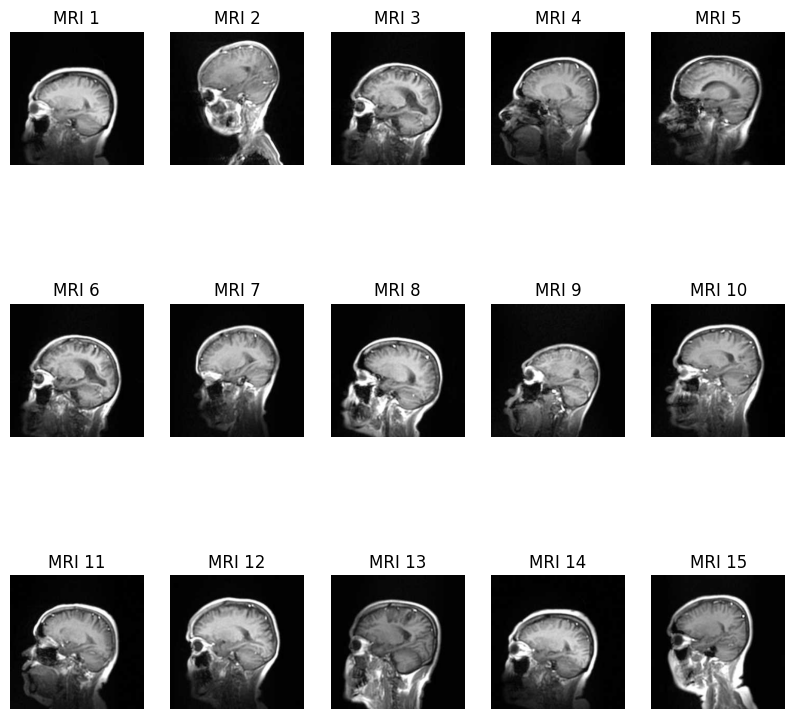

In [10]:
plt.figure(figsize = (10, 10)) #creating a figure with a size of 10x10 inches

for i in range(15): #Looping through the first 15 images in the X array
    plt.subplot(3,5, i+1) #creating a subplot with 3 rows and 3 columns
    plt.imshow(X[i]) #displaying the image at index i in the X array
    plt.title(f"MRI {i+1}") #adding a title to each subplot
    plt.axis("off") #turning off the axis for each subplot

plt.show() #displaying the figure with all subplots

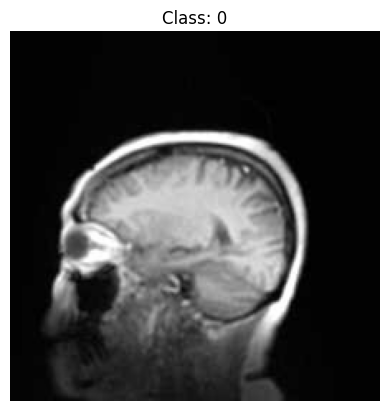

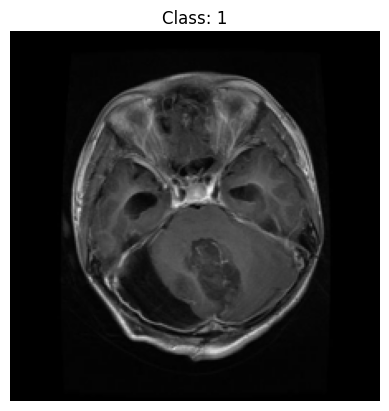

In [11]:
classes = np.unique(Y) #getting the unique classes in the Y array

for class_name in classes: #Looping through the unique classes
    index = np.where(Y == class_name)[0][0] #getting the index of the first occurrence of the class in the Y array

    plt.figure()
    plt.imshow(X[index]) #displaying the image at the index of the class
    plt.title(f"Class: {class_name}") #adding a title to the image with the class name
    plt.axis("off") #turning off the axis for the image
    plt.show() #displaying the image with the class name

### Splitting the data

In [12]:
# Using the train_test_split function from sklearn to split the data into training, testing, and validation sets

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, 
    Y, 
    test_size=0.25,
    random_state=42
)

X_test, X_val, Y_test, Y_val = train_test_split(
    X_temp, 
    Y_temp,
    test_size=0.5,
    random_state=42
) 

In [13]:
train_gen = ImageDataGenerator(
    rescale = 1./255, #rescaling the pixel values to be between 0 and 1
    rotation_range = 50, #randomly rotating the images by up to 50 degrees
    shear_range = 0.2, #randomly shearing the images by up to 20%
    zoom_range = 0.2, #randomly zooming the images by up to 20%
    horizontal_flip = True, #randomly flipping the images horizontally
    fill_mode = 'nearest' #filling in any missing pixels with the nearest pixel value
)

val_gen = ImageDataGenerator(
    rescale = 1./255
)

train_iterator = train_gen.flow(
    X_train, 
    Y_train, 
    batch_size = 32, #setting the batch size to 32
    shuffle = True #shuffling the data after each epoch
)

val_iterator = val_gen.flow(
    X_val, 
    Y_val, 
    batch_size = 16, 
    shuffle = False
)

LABEL: 0

IMAGE PIXEL ARRAY: 

[[[68 68 68]
  [32 32 32]
  [35 35 35]
  ...
  [35 35 35]
  [34 34 34]
  [69 69 69]]

 [[41 41 41]
  [ 3  3  3]
  [ 4  4  4]
  ...
  [ 3  3  3]
  [ 3  3  3]
  [38 38 38]]

 [[42 42 42]
  [ 6  6  6]
  [ 7  7  7]
  ...
  [ 6  6  6]
  [ 6  6  6]
  [41 41 41]]

 ...

 [[40 40 40]
  [ 2  2  2]
  [ 8  8  8]
  ...
  [ 7  7  7]
  [ 6  6  6]
  [42 42 42]]

 [[34 34 34]
  [ 0  0  0]
  [ 2  2  2]
  ...
  [ 3  3  3]
  [ 1  1  1]
  [36 36 36]]

 [[80 80 80]
  [48 48 48]
  [55 55 55]
  ...
  [52 52 52]
  [48 48 48]
  [79 79 79]]]




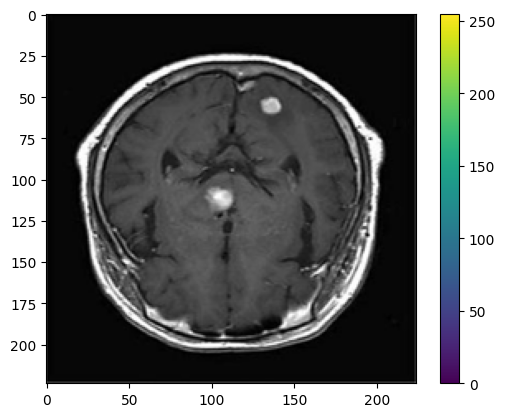

In [14]:
index = 0
np.set_printoptions(linewidth = 320) # setting the line width for printing numpy arrays to 320 characters

print(f'LABEL: {Y_train[index]}')
print(f'\nIMAGE PIXEL ARRAY: \n\n{X_train[index]}\n\n')

plt.imshow(X_train[index])
plt.colorbar()
plt.show()

In [15]:
X_train = X_train/255.0
X_test = X_test/255.0
X_val = X_val/255.0

In [16]:
print(X_train[0].shape) #printing the shape of the X array

(224, 224, 3)


### Model Creation

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape = (224, 224, 3)),

    tf.keras.layers.Conv2D(16, (3, 3), activation='relu'), #adding a convolutional layer with 16 filters, a kernel size of 3x3, and ReLU activation
    tf.keras.layers.MaxPooling2D(), #adding a max pooling layer with a pool size of 2x2

    tf.keras.layers.Conv2D(32, 3, activation='relu'), #adding a convolutional layer with 32 filters, a kernel size of 3x3, and ReLU activation
    tf.keras.layers.MaxPooling2D(), #adding a max pooling layer with a pool size of 2x2

    tf.keras.layers.Conv2D(64, 3, activation='relu'), #adding a convolutional layer with 64 filters, a kernel size of 3x3, and ReLU activation
    tf.keras.layers.MaxPooling2D(), #adding a max pooling layer with a pool size of 2x2

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Flatten(), #flattening the output of the previous layer to a 1D array

    tf.keras.layers.Dense(12568, activation='relu'), #adding a dense layer with 256 units and ReLU activation
    tf.keras.layers.Dense(1, activation='sigmoid') #adding a dense layer with 1 unit and sigmoid activation for binary classification
])

In [19]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001), #using the Adam optimizer with a learning rate of 0.001
    loss = 'binary_crossentropy', #using binary crossentropy loss for binary classification
    metrics = ['accuracy'] #monitoring accuracy as a metric
)

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12568)          │   543,754,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        12,569 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 543,790,673 (2.03 GB)

 Trainable params: 543,790,673 (2.03 GB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(
    train_iterator,
    validation_data = val_iterator,
    epochs = 20,
    batch_size = 32,
    callbacks = [myCallback()]
)

Epoch 1/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 390s 2s/step - accuracy: 0.8786 - loss: 0.3544 - val_accuracy: 0.9485 - val_loss: 0.1528
Epoch 2/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9486 - loss: 0.1484n\Accuracy is above 95% so cancelling training!
237/237 ━━━━━━━━━━━━━━━━━━━━ 385s 2s/step - accuracy: 0.9503 - loss: 0.1401 - val_accuracy: 0.9208 - val_loss: 0.1863


<Figure size 640x480 with 0 Axes>

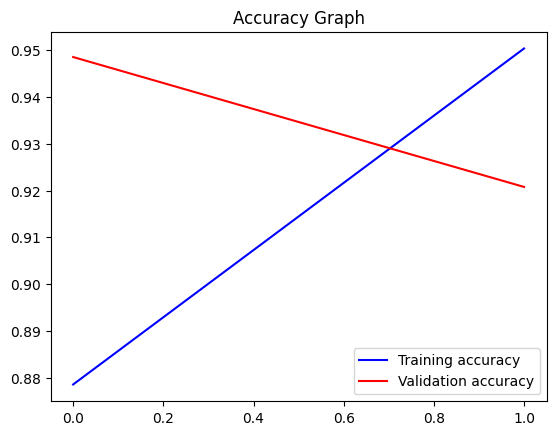

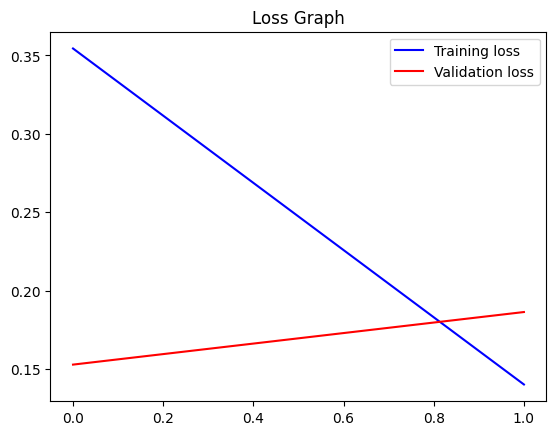

<Figure size 640x480 with 0 Axes>

In [23]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(len(acc))

plt.plot(epochs, acc, 'b', label = 'Training accuracy')
plt.plot(epochs, val_acc, 'r', label = 'Validation accuracy')
plt.title('Accuracy Graph')
plt.legend()
plt.figure()

loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(len(val_loss))

plt.plot(epochs, loss, 'b', label = 'Training loss')
plt.plot(epochs, val_loss, 'r', label = 'Validation loss')
plt.title('Loss Graph')
plt.legend()
plt.figure()

In [24]:
model.save("MRI_Tumor_detection.keras")